(1250, 9)
[ 0.07379675 -0.08104676 -0.05015094  0.01050958  0.0082114   0.01068452]
0.69132676816914
[-6.76436684e-16  6.89936996e-16  3.46744855e-16  8.66862138e-17
  8.31335001e-17  8.66862138e-17]


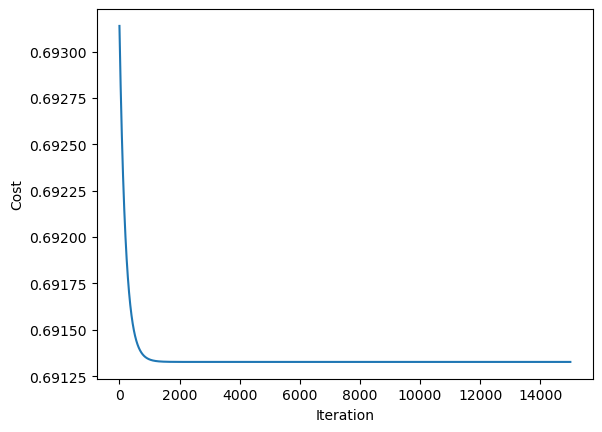

col_0    0    1
row_0          
0      116   98
1      486  550
[[1 1]
 [0 1]
 [0 0]
 [1 1]
 [1 1]
 [1 1]
 [0 0]
 [1 1]
 [1 1]
 [0 1]]
0.5328
Optimization terminated successfully.
         Current function value: 0.691327
         Iterations 4
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                 1250
Model:                          Logit   Df Residuals:                     1244
Method:                           MLE   Df Model:                            5
Date:                Thu, 01 Oct 2026   Pseudo R-squ.:                0.001651
Time:                        19:53:42   Log-Likelihood:                -864.16
converged:                       True   LL-Null:                       -865.59
Covariance Type:            nonrobust   LLR p-value:                    0.7219
                 coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------

In [25]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-


import numpy as np
import matplotlib.pyplot as plt
from ISLP import load_data
import pandas as pd


dat = load_data('Smarket')

print(dat.shape)
dat.head()

dat.describe()



predictors = [
    "Lag1",
    "Lag2",
    "Lag3",
    "Lag4",
    "Lag5"
]

x = dat[predictors].to_numpy(dtype=float)

mu = x.mean(axis=0)
sd = x.std(axis=0, ddof=1)

xs = (x - mu) / sd  # feature scaling


X = np.column_stack([np.ones(xs.shape[0]), xs])        # intercept, scaled predictor

y = (dat['Direction'] == 'Up').astype(int).to_numpy()   

# -------- sigmoid function
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


# -------- gradient descent 

# start values
n, p = X.shape
theta = np.zeros(p)

# hyperparameters 
alpha = 0.01
num_iters = 15000

J_history = []           # track the cost 


for i in range(num_iters):
    # prediction for every example
    fx = sigmoid(X @ theta)     

    ## error
    error = fx - y
    
    # gradient
    grad = (X.T @ error) / n

    
    # update parameters
    theta = theta - alpha * grad

    fx_current = sigmoid(X @ theta)

    cost = -np.mean(
        y * np.log(fx_current) +
        (1 - y) * np.log(1 - fx_current))
    
    J_history.append(cost)
    

print(theta)

column_names = [
    "Intercept",
    "Lag1",
    "Lag2",
    "Lag3",
    "Lag4",
    "Lag5",
    "Volume",
    "Direction"
]

dict(zip(column_names, theta))


print(J_history[-1])

# -------- check convergence
print(grad)   # close to zero

# cost function history
plt.plot(
    np.arange(1, num_iters + 1),
    J_history
)

plt.xlabel("Iteration")
plt.ylabel("Cost")

plt.show()


# --------- Classification results

probs = sigmoid(X @ theta)

# Classify using a probability threshold of 0.50
predy = (probs >= 0.50).astype(int)

# confusion matrix
print(pd.crosstab(predy, y))


accuracy = np.mean(predy == y)

print(np.column_stack([predy, y])[:10])

print(accuracy)


# ---------- compare with statsmodels library

import statsmodels.api as sm

model = sm.Logit(y, X)
result = model.fit()
print(result.summary())

probs_sm = result.predict(X)
predy_sm = (probs_sm >= 0.50).astype(int)

accuracy_sm = np.mean(predy_sm == y)
print(accuracy_sm)